In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 05 — What can the no-contract model predict? Theory and data

Three questions from the Inbox (26-10-29) and from Nir's paper outline ("predict these properties from the model;
1st vs 2nd order effects"):
1. **Can a perfect fit of the model with no contract tell us what a contract will do?** (the OOD question, and the
   "engineered function" idea: same base preference, totally different behaviour under a contract).
2. **Is the Apple decay predictable** from the no-contract weights?
3. **Can we predict how hard a request is to obey** from the no-contract weights — and does it relate to the feature's
   scale?

In [2]:
from grumish import *
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
setup_plots()
FIG = "figs/GRUMish"
R = load_all()
QG = [m for m in REAL if FAMILY[m] != "olmo"]

## 1. Theory: the no-contract data cannot identify what a contract does

In the GRUM, the utility of laptop *j* under contract *x* is u = (a + Bᵀx)ᵀ z_j. With **no contract, x = 0**, so every
no-contract choice depends on **a only**. B — everything a contract does — multiplies a zero and drops out of the
likelihood. **Any B fits the no-contract data equally well.** A perfect base model therefore predicts nothing about
conditionals; only (i) runs with a contract or (ii) an assumption about B (an inductive bias) can.

The demonstration below builds 5 GRUMs that are **identical with no contract** (they all have qwen-32B's real *a*), and
differ only in B. Then it asks each of them the `8GB` request:
- **real** — the B measured from qwen-32B's actual `ram=8GB` run;
- **ignores it** — B = 0: the request changes nothing;
- **obedient filter** — pushes 8GB to the top, touches nothing else;
- **over-reacts** — pushes 8GB and turns every other taste upside down (κ = 2: HP and 13-inch become the favourites);
- **chaos** — a random B row, three times as large as the real shift.

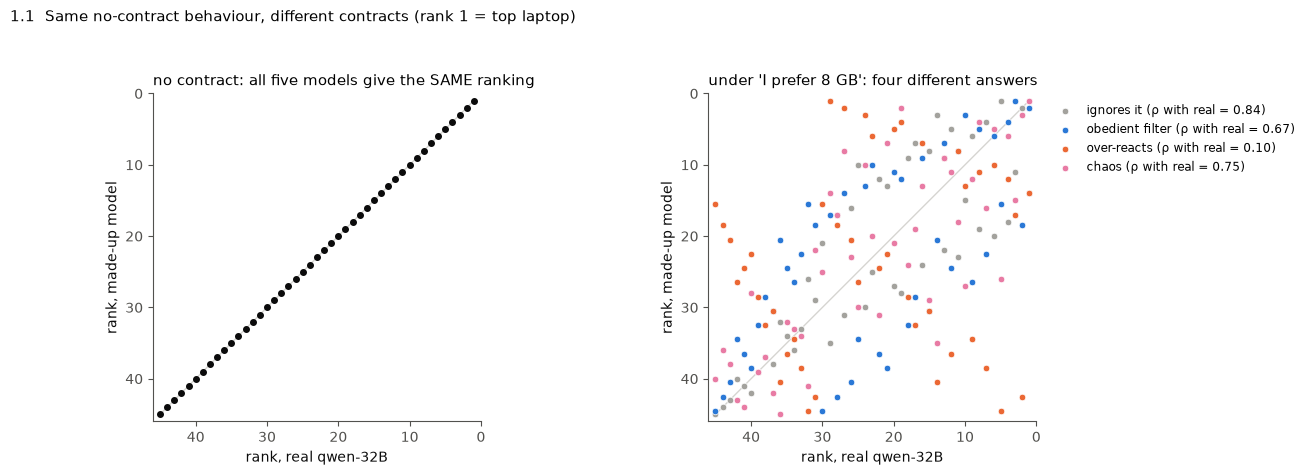

real             top 3 under 8GB: ['ASUS 16in 8GB', 'ASUS 16in 16GB', 'Apple 16in 8GB']   rho with real: +1.00
ignores it       top 3 under 8GB: ['Apple 16in 16GB', 'ASUS 16in 16GB', 'Apple 14in 16GB']   rho with real: +0.84
obedient filter  top 3 under 8GB: ['Apple 16in 8GB', 'ASUS 16in 8GB', 'Apple 14in 8GB']   rho with real: +0.67
over-reacts      top 3 under 8GB: ['HP 13in 8GB', 'Dell 13in 8GB', 'Lenovo 13in 8GB']   rho with real: +0.10
chaos            top 3 under 8GB: ['ASUS 16in 8GB', 'ASUS 13in 8GB', 'ASUS 16in 16GB']   rho with real: +0.75


In [3]:
m = "qwen-32B"; a = R[(m, "none")].w; real = R[(m, "ram=8GB")].w
rng = np.random.default_rng(3)
def made_up(rho, kappa):
    return predict_struct(a, {"sigma": {"ram": 1.0}, "rho": {"ram": rho}, "kappa": {("ram", g): kappa for g in FEATS}}, {"ram": "8GB"}, shape="peak")
noise = pd.Series(rng.normal(0, 3 * (real - a).std(), len(a)), index=a.index)
for f in FEATS: noise[f] = (noise[f] - noise[f].mean()).values
MOD = {"real": real, "ignores it": a, "obedient filter": made_up(30, 0.0), "over-reacts": made_up(30, 2.0), "chaos": a + noise}
cols = {"real": INK, "ignores it": GRAY, "obedient filter": BLUE, "over-reacts": ORANGE, "chaos": MAGENTA}
u0 = additive_utility(a); ureal = additive_utility(real)
rk = lambda u: pd.Series(u).rank(ascending=False).values
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(rk(u0), rk(u0), s=16, color=INK)
axes[0].set_title("no contract: all five models give the SAME ranking", loc="left")
for name, w in MOD.items():
    if name == "real": continue
    u = additive_utility(w)
    axes[1].scatter(rk(ureal), rk(u), s=22, color=cols[name], edgecolor="white", linewidth=0.5,
                    label=f"{name} (ρ with real = {spearmanr(ureal, u)[0]:.2f})")
axes[1].set_title("under 'I prefer 8 GB': four different answers", loc="left")
for ax in axes:
    ax.plot([1, 45], [1, 45], color=LGRAY, lw=1, zorder=0); ax.set_xlim(46, 0); ax.set_ylim(46, 0); ax.set_aspect("equal")
    ax.set_xlabel("rank, real qwen-32B"); ax.set_ylabel("rank, made-up model")
axes[1].legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle("1.1  Same no-contract behaviour, different contracts (rank 1 = top laptop)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(f"{FIG}/05_1_identification.png", dpi=150); plt.show()
for name, w in MOD.items():
    u = additive_utility(w); top = [lap_name(LAPTOPS[i]) for i in np.argsort(-u)[:3]]
    print(f"{name:16} top 3 under 8GB: {top}   rho with real: {spearmanr(ureal, u)[0]:+.2f}")

- **With no contract the five models cannot be told apart** (left: one ranking). Under `8GB` each has a different
  favourite: real **ASUS 16in 8GB**; "ignores it" Apple 16in 16GB; "obedient filter" Apple 16in 8GB; "over-reacts" HP 13in
  8GB. Spearman with the real ranking: 0.84, 0.67, 0.10, 0.75.
- **So the answer to the inbox question is no.** A perfect no-contract fit says nothing about conditionals; the B part of
  the GRUM is invisible at x = 0. This is the formal version of "the contract is an OOD shift".
- Note the real winner: not the "obedient filter" guess (Apple 16in 8GB) but ASUS. Assuming κ = 0 (a pure filter) misses
  the Apple decay. The inductive bias has to include leakage.

### So what is our inductive bias?

What the structured GRUM assumes about B, and what notebooks 02–04 found:

| | assumption | evidence | verdict |
|---|---|---|---|
| A1 | a contract acts through the **features** (no per-laptop effects) | oracle 0.92; R² 0.97–1.00 (laptops) — books 0.26–0.39 | laptops yes, books no |
| A2 | one push ρ and one flattening σ **per feature**, any level | R² 0.86–0.97 over 3 levels | yes |
| A3 | the push has an **ideal-point** shape on ordered features | better for RAM in 6/7 models | yes (new) |
| A4 | other features are only **shrunk** toward 0 (κ), never turned | brand: mostly; screen under 4GB: turns | mostly |
| A5 | leakage goes **down** the priority order only (RAM → screen → brand) | brand → RAM κ 0.16–0.20 | yes (2 models) |
| A6 | requirements combine as a **diluted sum** | 0.90 pair accuracy | yes |

Under these assumptions, one run per feature plus one compound pins down B. The rest of this notebook asks how much of
B can be guessed **without** any contract run.

## 2. The Apple decay is mostly shrinkage — a 2nd-order effect predicted by the base weights

If a request only shrinks the brand taste (A4), the change of each brand is Δw_b = −κ · a_b: **the brand liked most
falls most, the brand liked least rises most.** Apple is the top brand in every qwen and gemma model, so shrinkage alone
predicts that Apple falls the most. Below: every brand in every one-requirement spec run (dot), its no-contract weight
against its change. A line through 0 with slope −κ is pure shrinkage.

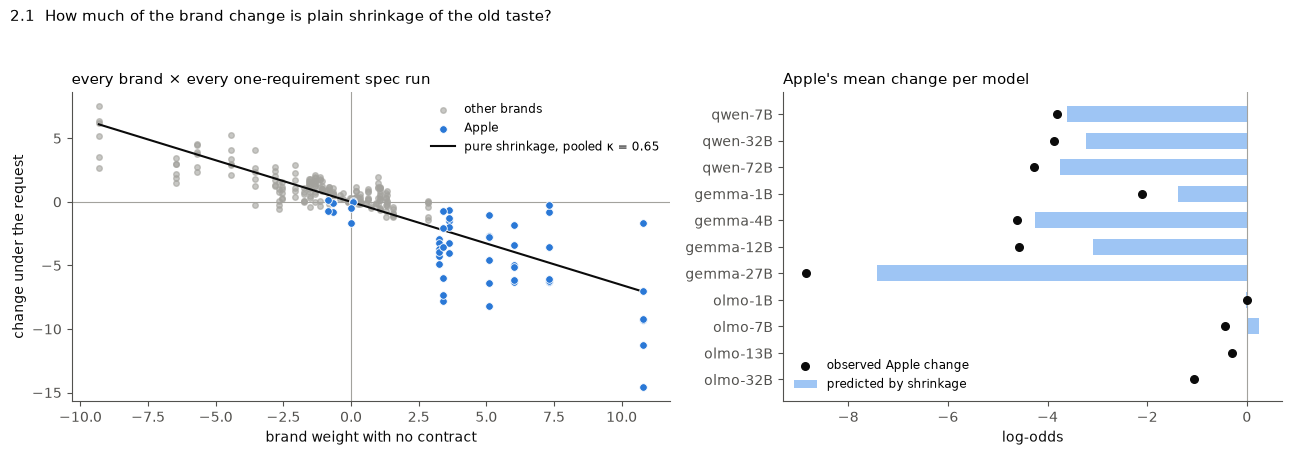

share of the brand change explained by shrinkage, per run: median 0.87 | IQR [0.73, 0.96]
Apple's extra fall beyond shrinkage (mean residual):
model
qwen-7B     -0.22
qwen-32B    -0.64
qwen-72B    -0.53
gemma-1B    -0.72
gemma-4B    -0.36
gemma-12B   -1.48
gemma-27B   -1.44
olmo-1B      0.01
olmo-7B     -0.68
olmo-13B    -0.32
olmo-32B    -1.06
Apple is the biggest faller in 45 of 50 runs


In [4]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if len(p) != 1 or "brand" in p or m == "qwen-0.5B": continue
    a = R[(m, "none")].w["brand"]; d = r.w["brand"] - a
    k = -float(d @ a / (a @ a))
    for b in BRANDS:
        rows.append(dict(model=m, c=c, brand=b, a=a[b], d=d[b], shrink=-k * a[b], resid=d[b] + k * a[b]))
AP = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
oth = AP[AP.brand != "Apple"]; app = AP[AP.brand == "Apple"]
ax.scatter(oth.a, oth.d, s=16, color=GRAY, alpha=0.6, label="other brands")
ax.scatter(app.a, app.d, s=30, color=BLUE, edgecolor="white", linewidth=0.6, label="Apple", zorder=3)
xx = np.linspace(AP.a.min(), AP.a.max(), 2); kk = -float(AP.d @ AP.a / (AP.a @ AP.a))
ax.plot(xx, -kk * xx, color=INK, lw=1.5, label=f"pure shrinkage, pooled κ = {kk:.2f}")
ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("brand weight with no contract"); ax.set_ylabel("change under the request"); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("every brand × every one-requirement spec run", loc="left")
ax = axes[1]
g = AP[AP.brand == "Apple"].groupby("model")[["d", "shrink", "resid"]].mean().reindex([m for m in REAL])
y = np.arange(len(g))
ax.barh(y, g.shrink, 0.6, color="#9ec5f4", label="predicted by shrinkage")
ax.scatter(g.d, y, color=INK, s=30, zorder=3, label="observed Apple change")
ax.axvline(0, color=GRAY, lw=0.8); ax.set_yticks(y, g.index); ax.invert_yaxis(); ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("Apple's mean change per model", loc="left"); ax.set_xlabel("log-odds")
fig.suptitle("2.1  How much of the brand change is plain shrinkage of the old taste?", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(f"{FIG}/05_2_apple_shrinkage.png", dpi=150); plt.show()
share = AP.groupby(["model", "c"]).apply(lambda s: 1 - (s.resid ** 2).sum() / (s.d ** 2).sum())
print("share of the brand change explained by shrinkage, per run: median", round(share.median(), 2), "| IQR", share.quantile([.25, .75]).round(2).tolist())
print("Apple's extra fall beyond shrinkage (mean residual):"); print(AP[AP.brand == "Apple"].groupby("model").resid.mean().reindex(REAL).round(2).to_string())
print("Apple is the biggest faller in", int(AP.loc[AP.groupby(["model", "c"]).d.idxmin()].brand.eq("Apple").sum()), "of", AP.groupby(["model", "c"]).ngroups, "runs")

- **Shrinkage explains most of the brand change**: median **87%** per run (middle half 73–96%). A request mostly turns
  the brand taste down, as A4 says.
- **So the Apple decay is mostly a 2nd-order effect predictable from the base weights**: the brand liked most falls most.
  Apple is the biggest faller in **45 of 50** one-requirement runs.
- **But Apple also falls a bit extra**, beyond shrinkage, in 10 of 11 models (−0.2 … −1.5 log-odds; largest in
  gemma-12B/27B and olmo-32B). Even OLMo, where Apple is not the favourite, shows it. This Apple-specific part is the
  one piece of the decay that the base weights do not predict (formalization §11: a second leakage component).

## 3. How hard is a request? Predicting obedience from the no-contract weights

Notebook 02 §2 found the requested level's lead after the contract ≈ intercept + slope × lead before. That is a
prediction **from the base weights alone**, once the two numbers per feature are known. Here: is the request obeyed
(the requested level beats every other level, with everything else equal), against how far behind it started?

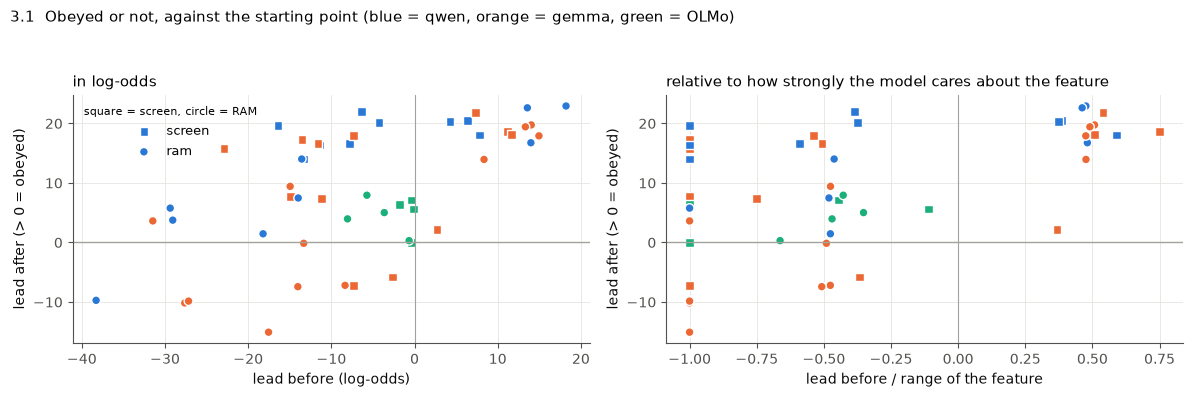

{'ram': 0.72, 'screen': 0.92}
RAM requests not obeyed:
    model   l     m0     m1  m0_rel
 qwen-32B 4GB -38.28  -9.72   -1.00
 gemma-1B 4GB -17.55 -15.07   -1.00
 gemma-4B 4GB -27.63 -10.15   -1.00
gemma-12B 4GB -27.17  -9.85   -1.00
 gemma-1B 8GB  -8.35  -7.20   -0.48
 gemma-4B 8GB -14.03  -7.42   -0.51
gemma-12B 8GB -13.32  -0.13   -0.49
RAM, obeyed vs m0_rel:
        min   max
obeyed           
False  -1.0 -0.48
True   -1.0  0.51


In [5]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if len(p) != 1 or m == "qwen-0.5B" or "brand" in p: continue
    (f, l), = p.items(); a = R[(m, "none")].w[f]; w = r.w[f]
    rng0 = R[(m, "none")].w[f].max() - R[(m, "none")].w[f].min()
    rows.append(dict(model=m, f=f, l=l, m0=a[l] - a.drop(l).max(), m1=w[l] - w.drop(l).max(), range0=rng0))
OB = pd.DataFrame(rows); OB["obeyed"] = OB.m1 > 0; OB["m0_rel"] = OB.m0 / OB.range0
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, lab in [(axes[0], "m0", "lead before (log-odds)"), (axes[1], "m0_rel", "lead before / range of the feature")]:
    for f, mk in [("screen", "s"), ("ram", "o")]:
        s = OB[OB.f == f]
        ax.scatter(s[col], s.m1, s=40, marker=mk, color=[FAMC[FAMILY[x]] for x in s.model], edgecolor="white", label=f)
    ax.axhline(0, color=GRAY, lw=1); ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_xlabel(lab); ax.set_ylabel("lead after (> 0 = obeyed)"); ax.grid(color=GRID, lw=0.6)
axes[0].legend(frameon=False, fontsize=9, title="square = screen, circle = RAM", title_fontsize=8)
axes[0].set_title("in log-odds", loc="left"); axes[1].set_title("relative to how strongly the model cares about the feature", loc="left")
fig.suptitle("3.1  Obeyed or not, against the starting point (blue = qwen, orange = gemma, green = OLMo)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIG}/05_3_obedience.png", dpi=150); plt.show()
print(OB.groupby("f").obeyed.mean().round(2).to_dict())
print("RAM requests not obeyed:"); print(OB[(OB.f == "ram") & ~OB.obeyed][["model", "l", "m0", "m1", "m0_rel"]].round(2).to_string(index=False))
print("RAM, obeyed vs m0_rel:"); print(OB[OB.f == "ram"].groupby("obeyed").m0_rel.describe()[["min", "max"]].round(2).to_string())

- **Screen requests are obeyed in 92% of runs, RAM requests in 72%.** Every failure is a RAM request for a level far
  below the favourite (`4GB`, or `8GB` in gemma-1/4/12B).
- **But the starting point does not decide who pays.** For `4GB` (the worst level, relative lead −1 in every model),
  three models obey (qwen-7B, qwen-72B, gemma-27B) and four do not (qwen-32B, gemma-1/4/12B), with overlapping
  starting leads (−29 … −31 vs −17 … −38).
- So the base weights tell **which** requests are risky, not **whether** a given model pays. Paying is a trait of the
  model, and costs one hard run per model to learn.

## 4. Do louder models push harder? (compliance vs the feature's scale)

Per model: the push ρ and flattening σ of notebook 02 (one per feature), against how strongly that model cares about
the feature with no contract (its range). If compliance were just "the model's own scale", ρ would grow in proportion.

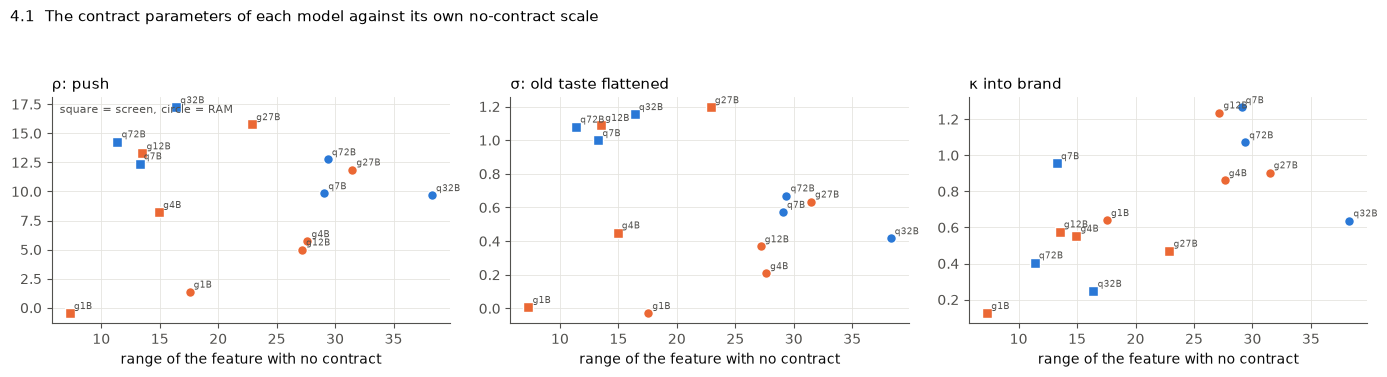

screen {'rho': np.float64(0.64), 'sigma': np.float64(0.75), 'kappa_brand': np.float64(0.18)} | rho/range: [0.93, 1.05, 1.26, -0.06, 0.55, 0.98, 0.69]
ram {'rho': np.float64(0.75), 'sigma': np.float64(0.71), 'kappa_brand': np.float64(-0.18)} | rho/range: [0.34, 0.25, 0.43, 0.08, 0.21, 0.18, 0.38]


In [6]:
rows = []
for m in QG:
    a = R[(m, "none")].w
    for f in ["screen", "ram"]:
        P = fit_struct(a, [(f, l, R[(m, f"{f}={l}")].w) for l in LEVELS[f]])
        rows.append(dict(model=m, f=f, rho=P["rho"][f], sigma=P["sigma"][f], range0=a[f].max() - a[f].min(),
                         kappa_brand=P["kappa"][(f, "brand")]))
SC = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, lab in zip(axes, ["rho", "sigma", "kappa_brand"], ["ρ: push", "σ: old taste flattened", "κ into brand"]):
    for f, mk in [("screen", "s"), ("ram", "o")]:
        s = SC[SC.f == f]
        for _, r in s.iterrows():
            st = model_style(r.model)
            ax.scatter(r.range0, r[col], s=50, marker=mk, color=st["color"], edgecolor="white")
            ax.annotate(r.model.replace("gemma-", "g").replace("qwen-", "q"), (r.range0, r[col]), xytext=(3, 3), textcoords="offset points", fontsize=6.5, color=INK2)
    ax.set_xlabel("range of the feature with no contract"); ax.set_title(lab, loc="left"); ax.grid(color=GRID, lw=0.6)
axes[0].text(0.02, 0.97, "square = screen, circle = RAM", transform=axes[0].transAxes, fontsize=8, va="top", color=INK2)
fig.suptitle("4.1  The contract parameters of each model against its own no-contract scale", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(f"{FIG}/05_4_scale.png", dpi=150); plt.show()
for f in ["screen", "ram"]:
    s = SC[SC.f == f]
    print(f, {c: round(spearmanr(s.range0, s[c])[0], 2) for c in ["rho", "sigma", "kappa_brand"]}, "| rho/range:", (s.rho / s.range0).round(2).tolist())

- **Louder models push harder**: ρ grows with the feature's no-contract range (Spearman 0.64 for screen, 0.75 for RAM).
- **Relative to the taste, the RAM push is much weaker**: ρ / range is 0.55–1.26 for screen (gemma-1B aside) but only
  **0.08–0.43** for RAM. That is the "compliance vs feature scale" answer: a RAM request moves the model by a smaller
  share of how much it cares about RAM — which is why RAM requests fail and screen requests do not.
- **Leakage into brand does not follow the scale** (Spearman 0.18 / −0.18).

## Summary: what the no-contract model tells, and what needs a contract run

| | predictable from the no-contract weights? |
|---|---|
| anything at all, in theory | **no** — B is not identified at x = 0 (section 1) |
| which brand falls under a spec request | **yes**: the top brand, by shrinkage (87% of the change; Apple 45/50) |
| which requests are risky | **yes**: the ones far below the favourite, on a high-priority feature |
| the size of the push | **roughly**: it grows with the feature's scale |
| whether a model pays for a hard request | **no** — a model trait (one hard run per model) |
| how much leakage, and its odd turns (`4GB` → smaller screen, Apple extra) | **no** — needs contract runs |

So with the inductive bias of section 1 (A1–A6), the minimal design per model is: the no-contract run, one run per
feature (preferably the hard level), and one compound run.